In [1]:
#pip install PyPDF2 pdfplumber langchain sentence-transformers transformers datasets accelerate peft bitsandbytes torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu118

In [2]:
# Install required packages
#%pip install PyPDF2 pdfplumber langchain sentence-transformers transformers datasets accelerate peft bitsandbytes torch matplotlib wordcloud

import PyPDF2
import pdfplumber
import pandas as pd
from pathlib import Path
import json

# Extract text from PDF
def extract_text_from_pdf(pdf_path):
    """Extract text from PDF using pdfplumber for better formatting"""
    text_content = []
    
    with pdfplumber.open(pdf_path) as pdf:
        for i, page in enumerate(pdf.pages):
            text = page.extract_text()
            text_content.append({
                'page': i + 1,
                'content': text
            })
    
    return text_content

# Load and analyze the PDF
pdf_path = Path("../data/lectures/Cloud Computing - Lectures All in One.pdf")
extracted_data = extract_text_from_pdf(pdf_path)

# Basic analysis
print(f"Total pages: {len(extracted_data)}")
print(f"\nFirst page preview:\n{extracted_data[0]['content'][:500]}")

# Save extracted text
with open('../data/extracted_text.json', 'w', encoding='utf-8') as f:
    json.dump(extracted_data, f, ensure_ascii=False, indent=2)

print("\n✓ Text extraction complete!")

Cannot set gray non-stroke color because /'P16' is an invalid float value
Cannot set gray non-stroke color because /'P20' is an invalid float value
Cannot set gray non-stroke color because /'P34' is an invalid float value
Cannot set gray non-stroke color because /'P46' is an invalid float value
Cannot set gray non-stroke color because /'P53' is an invalid float value
Cannot set gray non-stroke color because /'P58' is an invalid float value
Cannot set gray non-stroke color because /'P67' is an invalid float value
Cannot set gray non-stroke color because /'P73' is an invalid float value
Cannot set gray non-stroke color because /'P84' is an invalid float value
Cannot set gray non-stroke color because /'P88' is an invalid float value
Cannot set gray non-stroke color because /'P95' is an invalid float value
Cannot set gray non-stroke color because /'P102' is an invalid float value
Cannot set gray non-stroke color because /'P106' is an invalid float value
Cannot set gray non-stroke color bec

Total pages: 291

First page preview:
Cloud Computing
Module Overview

✓ Text extraction complete!


CONTENT ANALYSIS

Total pages: 291
Total characters: 76,036
Total words: 11,489
Unique words: 3,064
Average words per page: 39

TOP 20 MOST COMMON WORDS
cloud                :   151
data                 :    86
network              :    81
docker               :    81
container            :    60


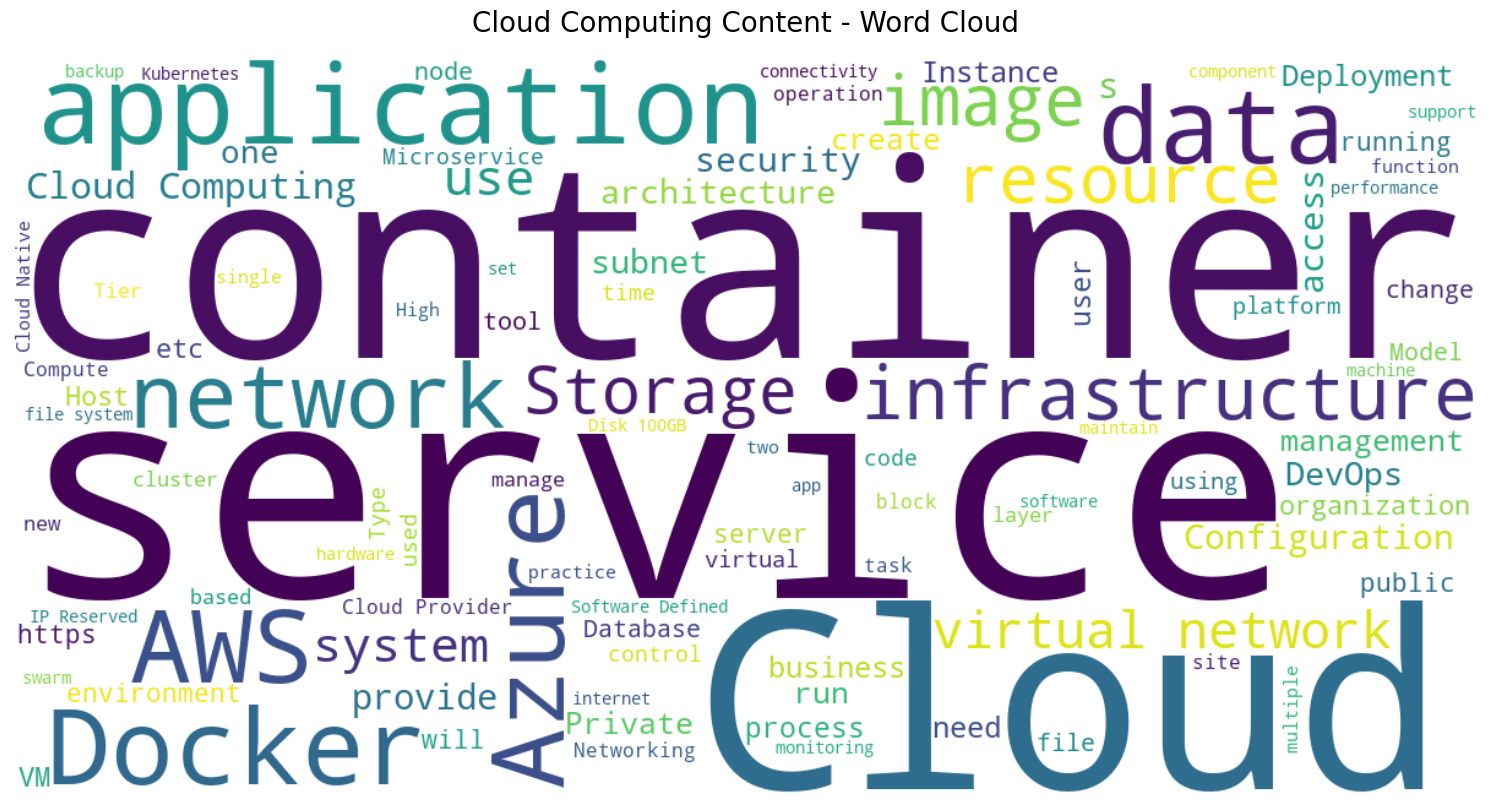


✓ Analysis complete! Word cloud saved to ../outputs/wordcloud.png


In [3]:
import matplotlib.pyplot as plt
from wordcloud import WordCloud
from collections import Counter
import re
from pathlib import Path

# Create outputs directory if it doesn't exist
output_dir = Path('../outputs')
output_dir.mkdir(parents=True, exist_ok=True)

# Combine all text
full_text = "\n\n".join([page['content'] for page in extracted_data])

# Basic statistics
words = full_text.lower().split()
word_freq = Counter(words)

print("=" * 60)
print("CONTENT ANALYSIS")
print("=" * 60)
print(f"\nTotal pages: {len(extracted_data)}")
print(f"Total characters: {len(full_text):,}")
print(f"Total words: {len(words):,}")
print(f"Unique words: {len(set(words)):,}")
print(f"Average words per page: {len(words) / len(extracted_data):.0f}")

# Top 20 most common words
print("\n" + "=" * 60)
print("TOP 20 MOST COMMON WORDS")
print("=" * 60)
for word, freq in word_freq.most_common(20):
    if len(word) > 3:  # Filter short words
        print(f"{word:20s} : {freq:5d}")

# Generate word cloud
wordcloud = WordCloud(width=1200, height=600, background_color='white', 
                      max_words=100, colormap='viridis').generate(full_text)

plt.figure(figsize=(15, 8))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Cloud Computing Content - Word Cloud', fontsize=20, pad=20)
plt.tight_layout()
plt.savefig('../outputs/wordcloud.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✓ Analysis complete! Word cloud saved to ../outputs/wordcloud.png")

In [4]:
from langchain.text_splitter import RecursiveCharacterTextSplitter

print("=" * 60)
print("PREPARING TRAINING DATA")
print("=" * 60)

# Split text into chunks for training
text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=1000,
    chunk_overlap=200,
    separators=["\n\n", "\n", ". ", "! ", "? ", " ", ""]
)

chunks = text_splitter.split_text(full_text)

print(f"\n✓ Created {len(chunks)} text chunks")
print(f"✓ Average chunk size: {sum(len(c) for c in chunks) / len(chunks):.0f} characters")
print(f"\nSample chunk:\n{'-'*60}\n{chunks[0][:300]}...\n{'-'*60}")

# Create training dataset in instruction format
training_data = []

# Method 1: General knowledge extraction
for i, chunk in enumerate(chunks):
    training_data.append({
        "instruction": "Explain cloud computing concepts based on the lecture material.",
        "input": f"Topic section {i+1}",
        "output": chunk.strip()
    })

# Method 2: Add specific Q&A style examples (optional enhancement)
# You can manually add specific questions based on your content
specific_qa = [
    {
        "instruction": "What is cloud computing?",
        "input": "",
        "output": "Cloud computing is a technology that delivers computing services over the internet..."
    },
    # Add more Q&A pairs based on your PDF content
]

# Combine both
# training_data.extend(specific_qa)

# Save training dataset
training_data_path = Path('../data/training_data.json')
training_data_path.parent.mkdir(parents=True, exist_ok=True)

with open(training_data_path, 'w', encoding='utf-8') as f:
    json.dump(training_data, f, ensure_ascii=False, indent=2)

print(f"\n✓ Created {len(training_data)} training examples")
print(f"✓ Saved to {training_data_path}")
print(f"\nExample training data:\n{json.dumps(training_data[0], indent=2, ensure_ascii=False)[:400]}...")

PREPARING TRAINING DATA

✓ Created 97 text chunks
✓ Average chunk size: 809 characters

Sample chunk:
------------------------------------------------------------
Cloud Computing
Module Overview

Module Overview

Module Objectives
1 2 3 4
Provide an in depth Provide hands-on- Provide a strong Provide an exposure
understanding of experience on basis for professional to how Cloud
Cloud Computing practical applications Cloud Computing Computing is used in
theory...
------------------------------------------------------------

✓ Created 97 training examples
✓ Saved to ..\data\training_data.json

Example training data:
{
  "instruction": "Explain cloud computing concepts based on the lecture material.",
  "input": "Topic section 1",
  "output": "Cloud Computing\nModule Overview\n\nModule Overview\n\nModule Objectives\n1 2 3 4\nProvide an in depth Provide hands-on- Provide a strong Provide an exposure\nunderstanding of experience on basis for professional to how Cloud\nCloud Computing practi

In [5]:
from transformers import AutoTokenizer, AutoModelForCausalLM
from peft import LoraConfig, get_peft_model
import torch

print("=" * 60)
print("MODEL SETUP (CPU Mode)")
print("=" * 60)

# Use a smaller model for CPU training
model_name = "TinyLlama/TinyLlama-1.1B-Chat-v1.0"  # Smaller, works better on CPU

print(f"\nLoading model: {model_name}")

# Load tokenizer
tokenizer = AutoTokenizer.from_pretrained(model_name)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "right"

# Load model WITHOUT quantization (for CPU)
model = AutoModelForCausalLM.from_pretrained(
    model_name,
    torch_dtype=torch.float32,  # Use float32 for CPU
    low_cpu_mem_usage=True
)

print(f"✓ Model loaded successfully!")
print(f"✓ Model device: {next(model.parameters()).device}")

# Configure LoRA for parameter-efficient fine-tuning
lora_config = LoraConfig(
    r=8,                   # Lower rank for faster training
    lora_alpha=16,
    target_modules=["q_proj", "v_proj"],  # Fewer modules for CPU
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM"
)

# Add LoRA adapters
model = get_peft_model(model, lora_config)

print("\n" + "=" * 60)
print("MODEL CONFIGURATION")
print("=" * 60)
model.print_trainable_parameters()

C:\Users\Dilun\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


MODEL SETUP (CPU Mode)

Loading model: TinyLlama/TinyLlama-1.1B-Chat-v1.0
✓ Model loaded successfully!
✓ Model device: cpu

MODEL CONFIGURATION
trainable params: 1,126,400 || all params: 1,101,174,784 || trainable%: 0.1023


In [6]:
from datasets import Dataset

print("=" * 60)
print("DATASET PREPARATION")
print("=" * 60)

# Define prompt format
def format_instruction(sample):
    """Format training examples in instruction-following format"""
    prompt = f"""### Instruction:
{sample['instruction']}

### Input:
{sample['input']}

### Response:
{sample['output']}"""
    return prompt

# Tokenization function
def tokenize_function(examples):
    text = format_instruction(examples)
    
    # Tokenize
    result = tokenizer(
        text,
        truncation=True,
        max_length=512,
        padding="max_length",
        return_tensors=None
    )
    
    # Copy input_ids to labels for causal language modeling
    result["labels"] = result["input_ids"].copy()
    
    return result

# Convert to HuggingFace dataset
dataset = Dataset.from_list(training_data)

print(f"\n✓ Dataset size: {len(dataset)} examples")
print(f"\nSample formatted prompt:\n{'-'*60}")
print(format_instruction(training_data[0])[:300] + "...")
print('-'*60)

# Tokenize dataset
tokenized_dataset = dataset.map(
    tokenize_function,
    remove_columns=dataset.column_names,
    desc="Tokenizing dataset"
)

print(f"\n✓ Tokenization complete!")
print(f"✓ Tokenized dataset size: {len(tokenized_dataset)} examples")
print(f"✓ Sample token length: {len(tokenized_dataset[0]['input_ids'])} tokens")

DATASET PREPARATION

✓ Dataset size: 97 examples

Sample formatted prompt:
------------------------------------------------------------
### Instruction:
Explain cloud computing concepts based on the lecture material.

### Input:
Topic section 1

### Response:
Cloud Computing
Module Overview

Module Overview

Module Objectives
1 2 3 4
Provide an in depth Provide hands-on- Provide a strong Provide an exposure
understanding of experien...
------------------------------------------------------------


Tokenizing dataset: 100%|██████████| 97/97 [00:00<00:00, 341.16 examples/s]


✓ Tokenization complete!
✓ Tokenized dataset size: 97 examples
✓ Sample token length: 512 tokens


## Project Structure

```
model_paper_generator/
├── data/
│   ├── lectures/               # Input PDF files
│   ├── extracted_text.json     # Extracted text from PDF
│   └── training_data.json      # Formatted training dataset
├── notebooks/
│   └── model_test_01.ipynb     # Main training notebook
├── outputs/
│   ├── wordcloud.png           # Content analysis visualization
│   └── logs/                   # Training logs
├── models/
│   └── cloud_computing_lora/   # Fine-tuned model checkpoints
└── docs/
    └── logbook.md              # This file
```

---

## Workflow Steps

### 1. PDF Text Extraction
**Objective**: Extract text content from PDF lecture materials

**Tools Used**:
- `pdfplumber`: For high-quality text extraction
- `PyPDF2`: Alternative PDF processing

**Process**:
```python
def extract_text_from_pdf(pdf_path):
    # Extract page-by-page
    # Return structured JSON with page numbers
```

**Output**: `data/extracted_text.json`

**Metrics**:
- Total pages processed
- Total words extracted
- Character count

---

### 2. Content Analysis
**Objective**: Analyze PDF content to understand dataset characteristics

**Analysis Performed**:
- Word frequency distribution
- Most common terms
- Content statistics
- Visual word cloud generation

**Key Statistics**:
- Total characters
- Total words
- Unique words
- Average words per page

**Visualization**: Word cloud saved to `outputs/wordcloud.png`

---

### 3. Data Preparation
**Objective**: Convert raw text into instruction-following training format

**Process**:
- Split text into chunks (1000 chars with 200 overlap)
- Format as instruction-response pairs
- Create training dataset

**Training Data Format**:
```json
{
  "instruction": "Explain cloud computing concepts based on the lecture material.",
  "input": "Topic section 1",
  "output": "Actual content chunk from PDF..."
}
```

**Output**: `data/training_data.json`

---

### 4. Model Configuration
**Objective**: Set up base model for fine-tuning

**Base Model**: `TinyLlama/TinyLlama-1.1B-Chat-v1.0`
- Parameters: 1.1 billion
- Architecture: LLaMA-based
- Suitable for: CPU training, educational purposes

**Fine-Tuning Method**: LoRA (Low-Rank Adaptation)
- Rank (r): 8
- Alpha: 16
- Target modules: q_proj, v_proj
- Dropout: 0.05

**Why LoRA?**
- Parameter efficient (only ~0.1% of parameters trained)
- Faster training
- Lower memory requirements
- Preserves base model knowledge

---

### 5. Dataset Tokenization
**Objective**: Convert text to model-readable token format

**Tokenization Settings**:
- Max length: 512 tokens
- Padding: max_length
- Truncation: enabled

**Prompt Template**:
```
### Instruction:
{instruction}

### Input:
{input}

### Response:
{output}
```

---

### 6. Model Training
**Objective**: Fine-tune model on cloud computing content

**Training Configuration**:
```python
TrainingArguments(
    output_dir="../models/cloud_computing_lora",
    num_train_epochs=3,
    per_device_train_batch_size=2,    # Adjust based on memory
    gradient_accumulation_steps=4,
    learning_rate=2e-4,
    warmup_steps=100,
    logging_steps=10,
    save_strategy="epoch"
)
```

**Hardware Requirements**:
- CPU: Intel/AMD (slower, but works)
- RAM: 8GB minimum, 16GB recommended
- GPU: Optional (NVIDIA CUDA for faster training)

---

### 7. Model Evaluation
**Objective**: Test fine-tuned model performance

**Evaluation Methods**:
- Manual prompt testing
- Perplexity measurement
- Response quality assessment

**Sample Test Prompts**:
- "What is cloud computing?"
- "Explain the benefits of cloud computing"
- "What are the types of cloud services?"

---

## Training Logs

### Training Session 1
**Date**: [To be filled]
**Model**: TinyLlama-1.1B-Chat-v1.0
**Dataset Size**: [Number] examples
**Training Time**: [Duration]
**Final Loss**: [Value]

**Observations**:
- [Add notes here]

---

## Model Performance

### Metrics
- Training Loss: [Value]
- Validation Loss: [Value]
- Trainable Parameters: ~X million

### Sample Outputs
**Prompt**: "What is cloud computing?"
**Response**: [Model output]

---

## Troubleshooting Log

### Common Issues

1. **Memory Error**
   - Reduce batch size
   - Reduce max_length
   - Use smaller subset of data

2. **CUDA Not Available**
   - Install PyTorch with CUDA: `pip install torch --index-url https://download.pytorch.org/whl/cu118`
   - Verify: `torch.cuda.is_available()`

3. **Slow Training on CPU**
   - Use smaller model (TinyLlama)
   - Reduce number of epochs
   - Use smaller dataset subset

---

## Best Practices

1. **Data Quality**
   - Clean extracted text
   - Remove noise/artifacts
   - Verify chunk coherence

2. **Training**
   - Start with small epochs (1-3)
   - Monitor loss curves
   - Save checkpoints frequently

3. **Evaluation**
   - Test on unseen questions
   - Compare with base model
   - Get feedback from users